In [9]:
import geopandas as gpd
import pandas as pd
import os
import matplotlib.pyplot as plt


In [13]:
TARGET_COUNTRY = "IND"
TARGET_REGION = "TN"
DATA_DIR = "data/raw"

TO_SAVE_DIR = os.path.join("..", "data", "interim")
CURRENT_DIR = os.getcwd()
print(CURRENT_DIR)

/home/peaceofsense/repos/pmm-tn/notebooks


In [14]:
geojson_file = os.path.join("..", DATA_DIR, "country_shapes.geojson")
country_df = gpd.read_file(geojson_file)

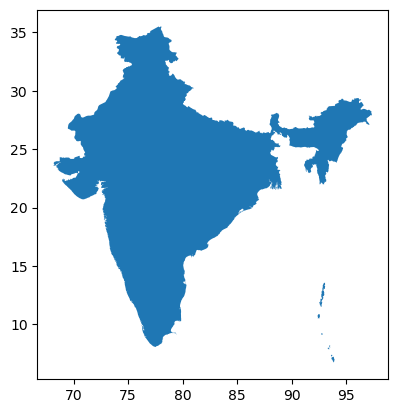

In [15]:
india_country_df = country_df[country_df['name'] == 'IN']
india_country_df = gpd.GeoDataFrame(india_country_df, geometry='geometry')
india_country_df.plot()

output_path = os.path.join(TO_SAVE_DIR, "india_geometry.geojson")
india_country_df.to_file(output_path, driver="GeoJSON")   

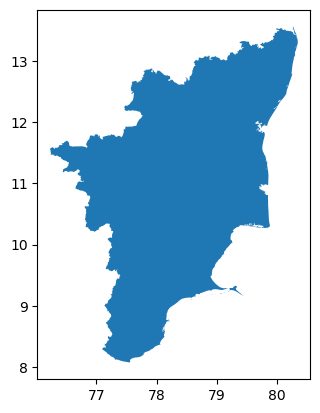

In [5]:
gadm_file = os.path.join("..", DATA_DIR, "gadm_410-levels-ADM_1-IND.gpkg")
gadm_india = gpd.read_file(gadm_file)
gadm_TN = gadm_india[gadm_india["GID_1"] == "IND.31_1"]
gadm_TN = gpd.GeoDataFrame(gadm_TN, geometry='geometry')
gadm_TN.plot()

output_path = os.path.join(TO_SAVE_DIR, "gadm_tamilnadu_LVL-1.gpkg")
gadm_TN.to_file(output_path, driver="GPKG")  

/home/peaceofsense/.conda/envs/esm/lib/python3.13/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'gadm41_IND.gpkg': 'ADM_ADM_0' (default), 'ADM_ADM_1', 'ADM_ADM_2', 'ADM_ADM_3'. Specify layer parameter to avoid this warning.
  result = read_func(


,GID_2,GID_0,COUNTRY,GID_1,NAME_1,NL_NAME_1,NAME_2,VARNAME_2,NL_NAME_2,TYPE_2,ENGTYPE_2,CC_2,HASC_2,geometry
0,IND.1.1_1,IND,India,IND.1_1,Andaman and Nicobar,NA,Nicobar Islands,NA,NA,District,District,NA,IN.AN.NI,"MULTIPOLYGON (((93.78988 6.85201, 93.79015 6.8..."
1,IND.1.2_1,IND,India,IND.1_1,Andaman and Nicobar,NA,North and Middle Andaman,NA,NA,District,District,NA,IN.AN.NM,"MULTIPOLYGON (((92.84441 12.14969, 92.84466 12..."
2,IND.1.3_1,IND,India,IND.1_1,Andaman and Nicobar,NA,South Andaman,NA,NA,District,District,NA,IN.AN.SA,"MULTIPOLYGON (((92.52111 10.89694, 92.52306 10..."
3,IND.2.1_1,IND,India,IND.2_1,Andhra Pradesh,NA,Anantapur,"Anantpur, Ananthapur",NA,District,District,NA,IN.AD.AN,"MULTIPOLYGON (((77.846 13.92832, 77.83012 13.9..."
4,IND.2.2_1,IND,India,IND.2_1,Andhra Pradesh,NA,Chittoor,Chitoor|Chittor,NA,District,District,NA,IN.AD.CH,"MULTIPOLYGON (((78.54555 12.74391, 78.55031 12..."


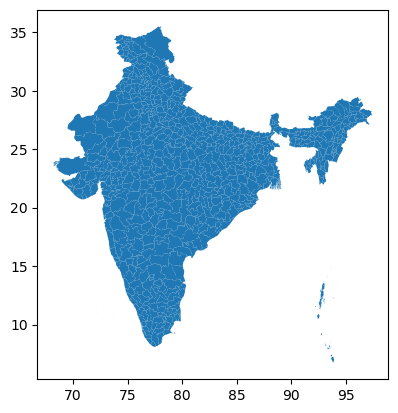

In [16]:
gadm_file = os.path.join("..", DATA_DIR, "gadm41_IND.gpkg")
gadm_india = gpd.read_file(gadm_file)
india_districts_df = gpd.read_file(
    gadm_file,
    layer="ADM_ADM_2"
)
india_districts_df.plot()

'''
tn_districts = gpd.sjoin(
    india_districts,
    gadm_TN,
    how="inner",
    predicate="within"
)
'''
india_districts_df.head()

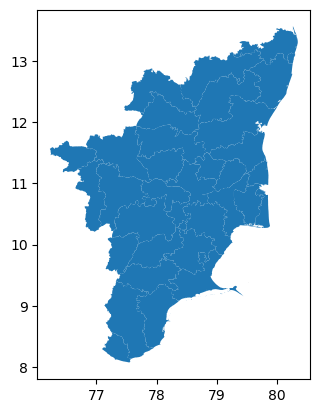

In [20]:
tn_districts = india_districts_df[india_districts_df["NAME_1"] == "Tamil Nadu"].copy()
tn_districts.plot()

output_path = os.path.join(TO_SAVE_DIR, "gadm_tamilnadu_LVL-2.gpkg")
#tn_districts.to_file(output_path, driver="GPKG")

### WRI Global Powerplant data

In [21]:
gppd = os.path.join("..", DATA_DIR, "global_power_plant_database.csv")
gppd_df = pd.read_csv(gppd)
gppd_india = gppd_df[gppd_df["country_long"] == "India"].copy()
gppd_india.head()

/tmp/ipykernel_3469103/3458074444.py:2: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  gppd_df = pd.read_csv(gppd)


,country,country_long,name,gppd_idnr,capacity_mw,latitude,longitude,primary_fuel,other_fuel1,other_fuel2,...,estimated_generation_gwh_2013,estimated_generation_gwh_2014,estimated_generation_gwh_2015,estimated_generation_gwh_2016,estimated_generation_gwh_2017,estimated_generation_note_2013,estimated_generation_note_2014,estimated_generation_note_2015,estimated_generation_note_2016,estimated_generation_note_2017
14052,IND,India,ACME Solar Tower,WRI1020239,2.5,28.1839,73.2407,Solar,NaN,NaN,...,4.37,4.73,4.49,4.26,4.29,SOLAR-V1,SOLAR-V1,SOLAR-V1,SOLAR-V1,SOLAR-V1
14053,IND,India,ADITYA CEMENT WORKS,WRI1019881,98.0,24.7663,74.6090,Coal,NaN,NaN,...,NaN,NaN,NaN,NaN,516.25,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,CAPACITY-FACTOR-V1
14054,IND,India,AES Saurashtra Windfarms,WRI1026669,39.2,21.9038,69.3732,Wind,NaN,NaN,...,NaN,NaN,NaN,NaN,56.88,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,CAPACITY-FACTOR-V1
14055,IND,India,AGARTALA GT,IND0000001,135.0,23.8712,91.3602,Gas,NaN,NaN,...,NaN,NaN,NaN,NaN,424.77,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,CAPACITY-FACTOR-V1
14056,IND,India,AKALTARA TPP,IND0000002,1800.0,21.9603,82.4091,Coal,Oil,NaN,...,NaN,NaN,NaN,NaN,9482.32,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,CAPACITY-FACTOR-V1


In [22]:
gppd_india = gpd.GeoDataFrame(
    gppd_india,
    geometry=gpd.points_from_xy(
        gppd_india["longitude"],
        gppd_india["latitude"]
    ),
    crs="EPSG:4326"
)

tn_districts = tn_districts.to_crs(gppd_india.crs)

gppd_tn = gpd.sjoin(
    gppd_india,
    tn_districts,
    how="inner",
    predicate="within"
)

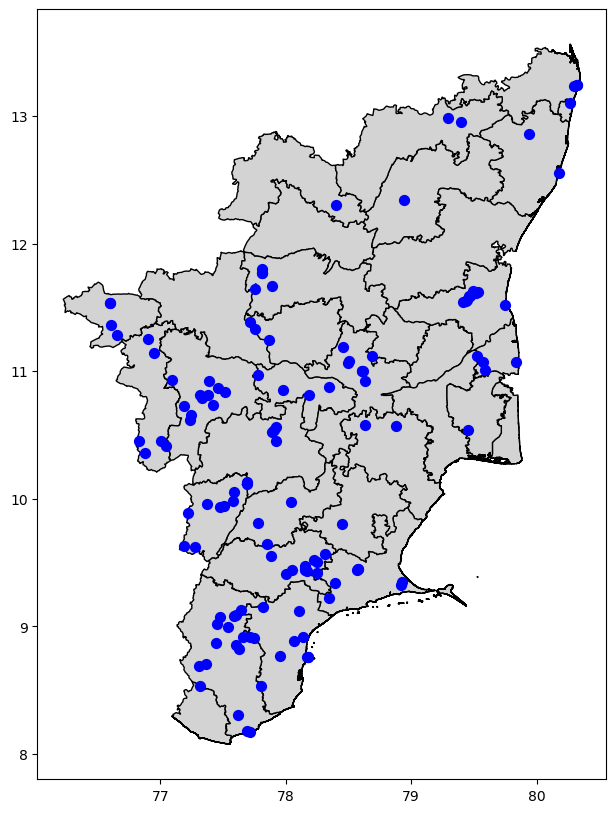

In [23]:
fig, ax = plt.subplots(figsize=(10, 10))

tn_districts.plot(ax=ax, color="lightgrey", edgecolor="black")

gppd_tn.plot(
    ax=ax,
    color="blue",
    markersize=50
)

plt.show()

In [24]:
gppd_tn

,country,country_long,name,gppd_idnr,capacity_mw,latitude,longitude,primary_fuel,other_fuel1,other_fuel2,...,GID_1,NAME_1,NL_NAME_1,NAME_2,VARNAME_2,NL_NAME_2,TYPE_2,ENGTYPE_2,CC_2,HASC_2
14058,IND,India,ALIYAR,IND0000004,60.00,10.4547,77.0078,Hydro,NaN,NaN,...,IND.31_1,Tamil Nadu,NA,Coimbatore,NA,NA,District,District,NA,IN.TN.CM
14080,IND,India,Agaram A,WKS0069517,20.00,10.4560,77.9240,Solar,NaN,NaN,...,IND.31_1,Tamil Nadu,NA,Dindigul,Anna,NA,District,District,NA,IN.TN.DI
14094,IND,India,Amathur,WKS0068271,14.40,9.5530,77.8850,Solar,NaN,NaN,...,IND.31_1,Tamil Nadu,NA,Virudunagar,Kamarajar,NA,District,District,NA,IN.TN.VR
14105,IND,India,Anikkadavu Wind Farm,WRI1026347,19.80,10.7245,77.1893,Wind,NaN,NaN,...,IND.31_1,Tamil Nadu,NA,Tiruppur,Periyar,NA,District,District,NA,IN.TN.TP
14106,IND,India,Apollo Chennai,WKS0073932,10.00,12.8570,79.9440,Solar,NaN,NaN,...,IND.31_1,Tamil Nadu,NA,Kancheepuram,NA,NA,District,District,NA,IN.TN.KC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15600,IND,India,Vedasandur,WKS0067248,5.00,10.5254,77.8899,Solar,NaN,NaN,...,IND.31_1,Tamil Nadu,NA,Dindigul,Anna,NA,District,District,NA,IN.TN.DI
15620,IND,India,Walaja,WKS0067244,5.00,12.9550,79.3950,Solar,NaN,NaN,...,IND.31_1,Tamil Nadu,NA,Vellore,North Arcot,NA,District,District,NA,IN.TN.VE
15624,IND,India,Weizzmann Forex Idukki Wind Farm,WRI1026760,3.60,9.8881,77.2216,Wind,NaN,NaN,...,IND.31_1,Tamil Nadu,NA,Theni,NA,NA,District,District,NA,IN.TN.TH
15625,IND,India,Wind power project by Riddhi Siddhi Gluco Biol...,WRI1026753,34.65,8.8709,77.4466,Wind,NaN,NaN,...,IND.31_1,Tamil Nadu,NA,Tirunelveli,NA,NA,District,District,NA,IN.TN.TI


In [27]:
output_path = os.path.join("..", "data", "interim", "tamil_nadu_powerplants.csv")
gppd_tn.to_csv(output_path)